# Schoebcast — KLO ICON Postprocessing

Step-by-step interactive notebook for loading KLO observations + ICON-CH1-EPS forecasts, inspecting the raw ICON baseline, and training/evaluating a small PyTorch postprocessor.

In [1]:
%load_ext autoreload
%autoreload 2

import torch
from core import data, model, utils

print("Station:", utils.STATION)
print("Data dir:", utils.DATA_DIR)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

Station: KLO
Data dir: C:\Users\marco\Documents\Programmieren\vibeweather\schoebcast\data
Device: NVIDIA GeForce RTX 4070 SUPER


## 1. Load KLO Data, Seasonal Block Splits & PyTorch DataLoaders

Loads 24h KLO observation lookbacks (`temperature`, `wind_u`, `wind_v`) aligned with 33h ICON-CH1-EPS 11-member ensemble forecasts, applies 24-day seasonal block splits separated by **36h buffer gaps** (zero target leakage), and builds normalized PyTorch `DataLoader`s.

In [2]:
raw = data.load_klo_data()
splits = data.make_block_splits(raw["reftime"])
loaders, scaler = data.build_dataloaders(raw, splits, batch_size=64)

print(f"Total valid ICON runs: {len(raw['reftime'])} ({raw['reftime'][0]} -> {raw['reftime'][-1]})")
print("Split run counts:", {k: len(v) for k, v in splits.items()})

batch = next(iter(loaders["train"]))
print("Sample PyTorch batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})

Total valid ICON runs: 4094 (2024-05-15 12:00:00+00:00 -> 2025-10-12 15:00:00+00:00)
Split run counts: {'train': 2510, 'val': 412, 'test': 420}
Sample PyTorch batch shapes: {'x_obs': (64, 24, 3), 'x_nwp': (64, 33, 11), 'icon_mean': (64, 33), 'y': (64, 33), 'mask': (64, 33)}


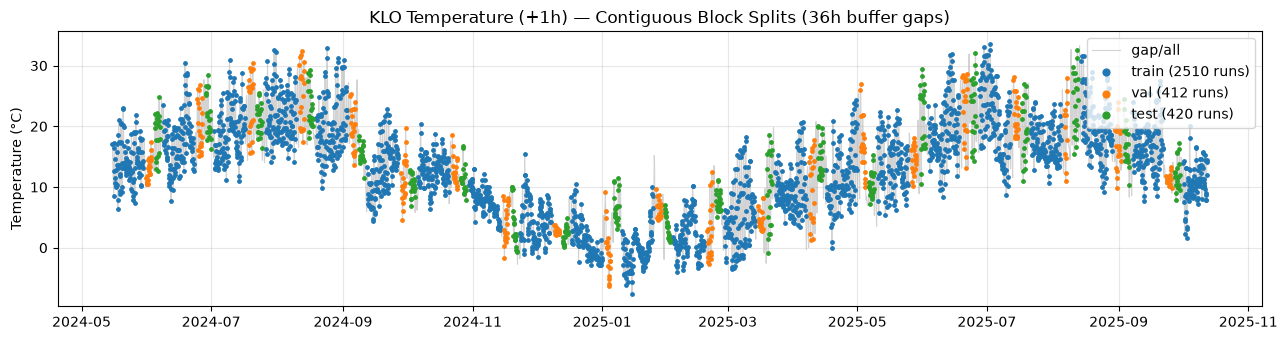

In [3]:
utils.plot_split_timeline(raw["reftime"], raw["y_temp"], splits)

## 2. Raw ICON-CH1-EPS Baseline on KLO

Measure raw ICON ensemble-mean MAE, RMSE, and Bias across the 33h forecast horizon on the validation and test splits — these are the exact benchmark numbers our PyTorch postprocessor needs to beat.

In [4]:
icon_val_metrics = utils.compute_metrics(
    y_true=raw["y_temp"][splits["val"]],
    y_pred=raw["icon_temp_mean"][splits["val"]],
    mask=raw["mask_y"][splits["val"]],
)
icon_test_metrics = utils.compute_metrics(
    y_true=raw["y_temp"][splits["test"]],
    y_pred=raw["icon_temp_mean"][splits["test"]],
    mask=raw["mask_y"][splits["test"]],
)

utils.summarize_metrics_table(
    {
        "ICON mean (Val)": icon_val_metrics,
        "ICON mean (Test)": icon_test_metrics,
    }
)

,MAE (°C),RMSE (°C),Bias (°C),runs
model,,,,
ICON mean (Val),0.988,1.312,-0.260,412
ICON mean (Test),0.931,1.199,-0.371,420


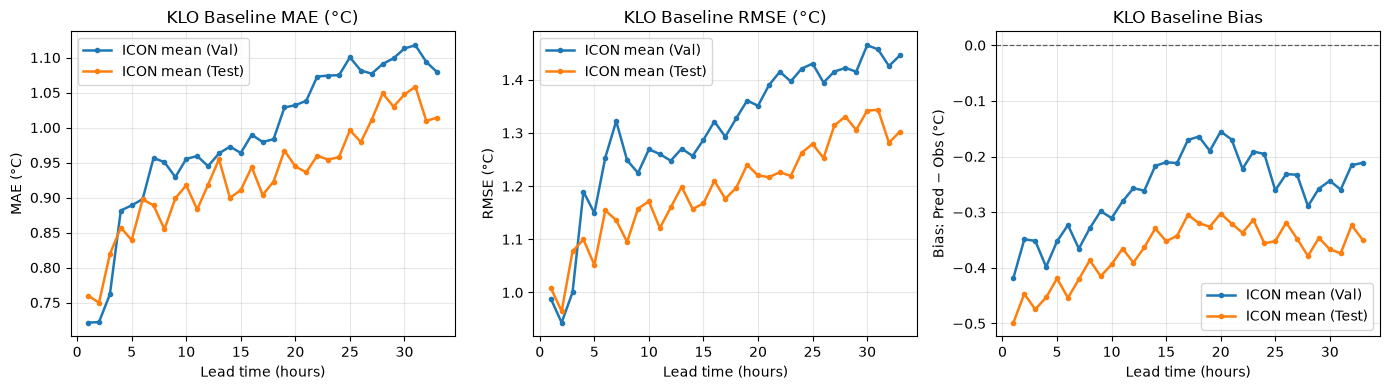

In [5]:
utils.plot_lead_metrics(
    {
        "ICON mean (Val)": icon_val_metrics,
        "ICON mean (Test)": icon_test_metrics,
    },
    split_label="KLO Baseline",
)

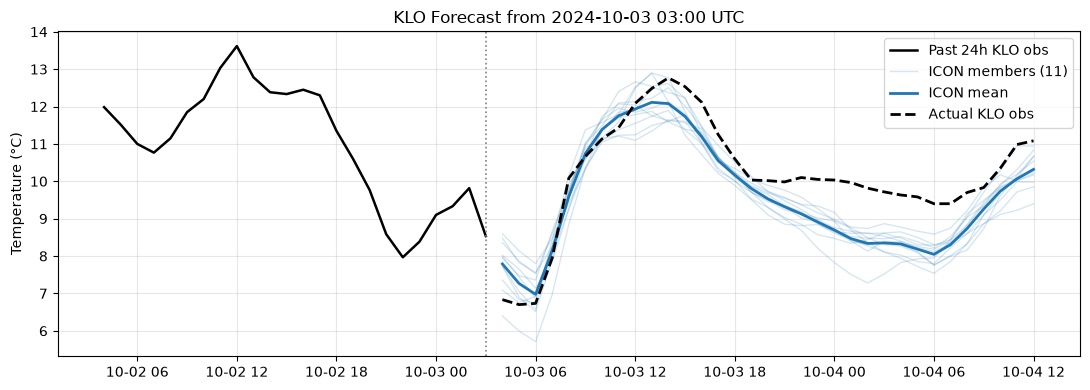

In [11]:
# Inspect a sample test forecast run (change test_k to browse winter/summer runs)
test_k = 105
utils.plot_sample_forecast(raw, run_idx=int(splits["test"][test_k]))

## 3. Train & Evaluate `SchoebcastGRU` on KLO

Train the small Encoder–Decoder GRU residual postprocessor (`y_hat = icon_mean + ΔT`), compare against the raw ICON-CH1-EPS baseline by lead hour, and save the checkpoint.

Trainable parameters: 18,017
Epoch 01/40 | train_loss: 0.7415 | val_loss: 0.7024 | val_MAE: 0.920 °C
Epoch 05/40 | train_loss: 0.6209 | val_loss: 0.6273 | val_MAE: 0.840 °C
Epoch 10/40 | train_loss: 0.5500 | val_loss: 0.6032 | val_MAE: 0.814 °C
Epoch 15/40 | train_loss: 0.5126 | val_loss: 0.6126 | val_MAE: 0.824 °C
Early stopping at epoch 18 (best epoch 8: 0.812 °C)
Restored best model from epoch 8 (val MAE = 0.812 °C)


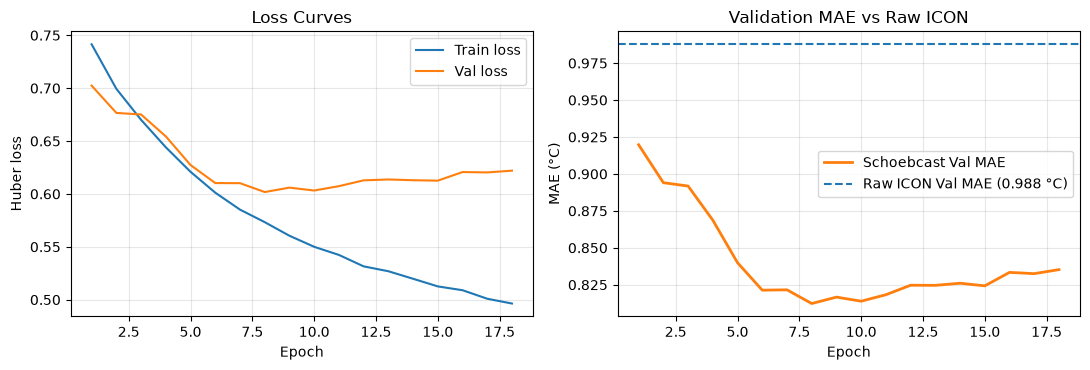

In [12]:
torch.manual_seed(42)

net = model.SchoebcastGRU(enc_hidden=32, dec_hidden=32, dropout=0.15)
print(f"Trainable parameters: {model.count_parameters(net):,}")

history = model.train_model(net, loaders, epochs=40, lr=1.5e-3, patience=10)
utils.plot_training_history(history, baseline_val_mae=icon_val_metrics["mae"])

In [13]:
val_preds = model.predict(net, loaders["val"])
test_preds = model.predict(net, loaders["test"])

sc_val_metrics = utils.compute_metrics(
    y_true=raw["y_temp"][splits["val"]],
    y_pred=val_preds,
    mask=raw["mask_y"][splits["val"]],
)
sc_test_metrics = utils.compute_metrics(
    y_true=raw["y_temp"][splits["test"]],
    y_pred=test_preds,
    mask=raw["mask_y"][splits["test"]],
)

utils.summarize_metrics_table(
    {
        "ICON mean (Val)": icon_val_metrics,
        "Schoebcast GRU (Val)": sc_val_metrics,
        "ICON mean (Test)": icon_test_metrics,
        "Schoebcast GRU (Test)": sc_test_metrics,
    }
)

,MAE (°C),RMSE (°C),Bias (°C),runs
model,,,,
ICON mean (Val),0.988,1.312,-0.260,412
Schoebcast GRU (Val),0.812,1.134,0.082,412
ICON mean (Test),0.931,1.199,-0.371,420
Schoebcast GRU (Test),0.818,1.088,-0.013,420


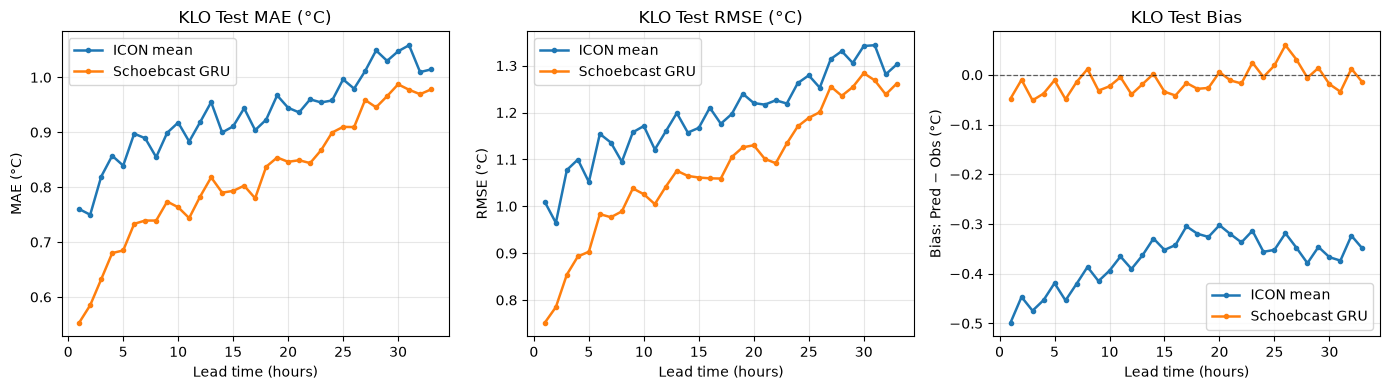

In [14]:
utils.plot_lead_metrics(
    {
        "ICON mean": icon_test_metrics,
        "Schoebcast GRU": sc_test_metrics,
    },
    split_label="KLO Test",
)

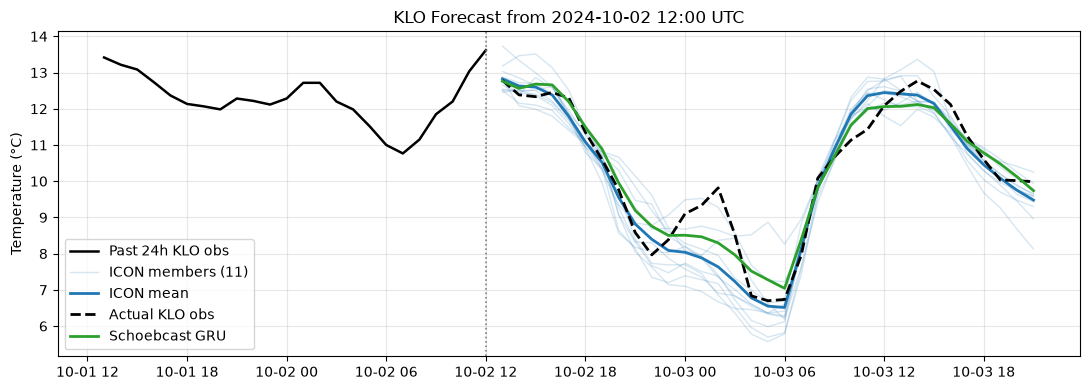

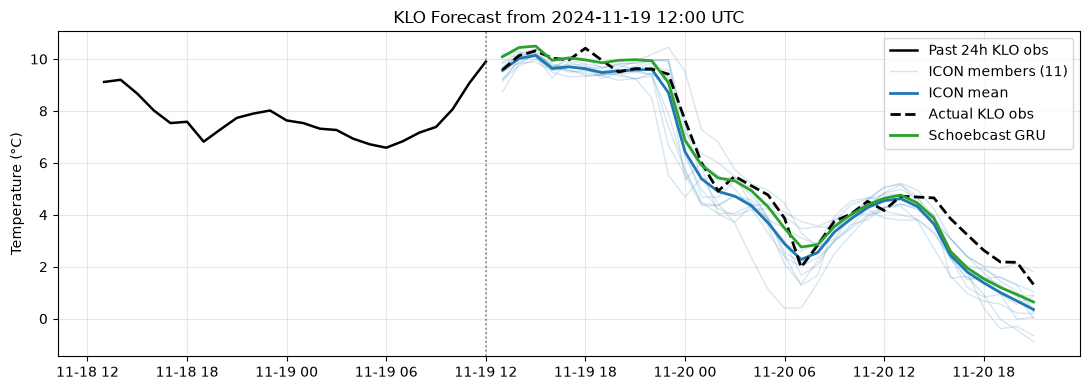

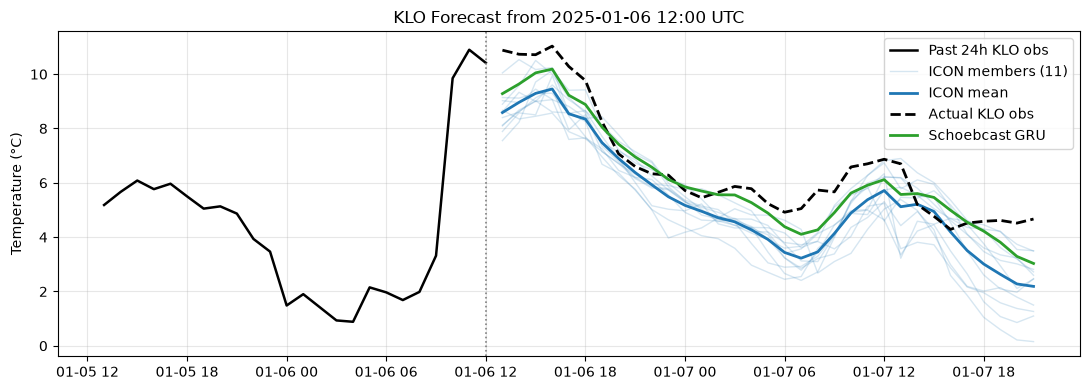

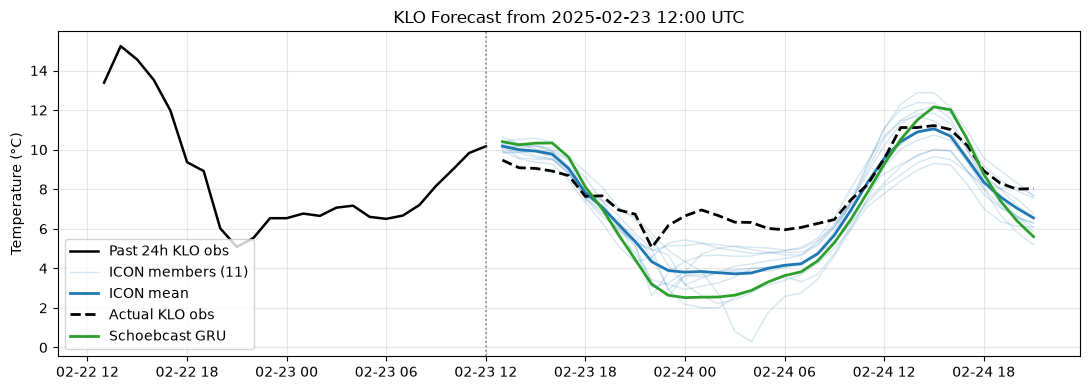

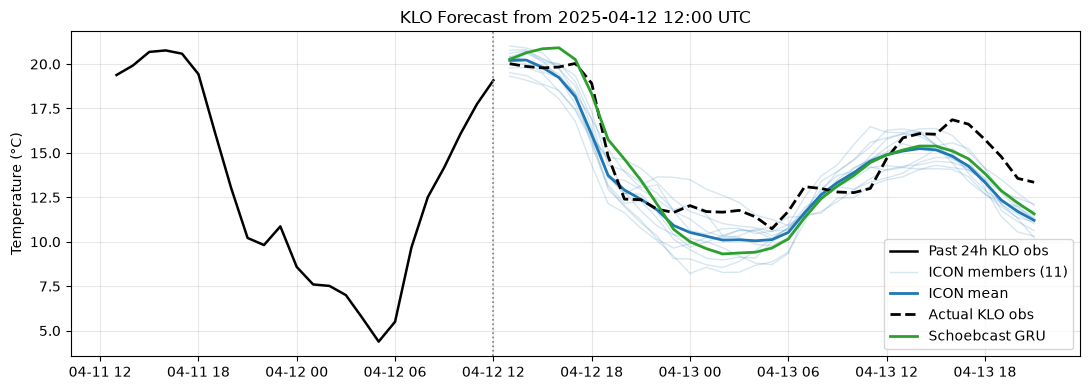

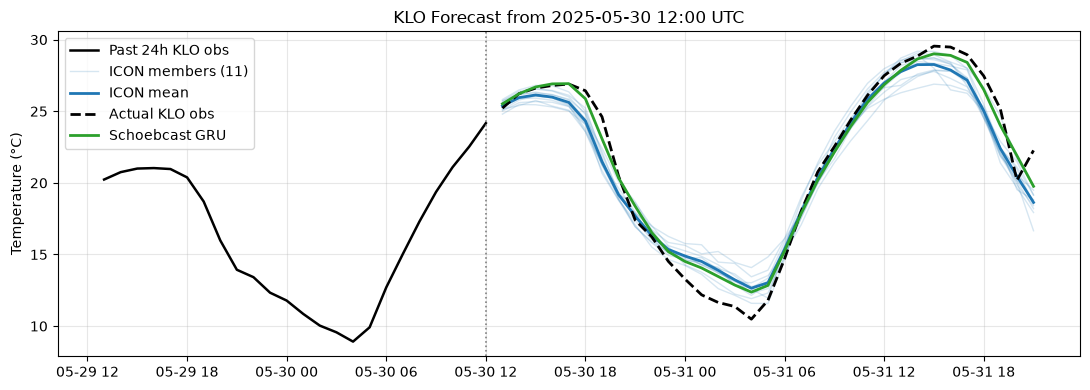

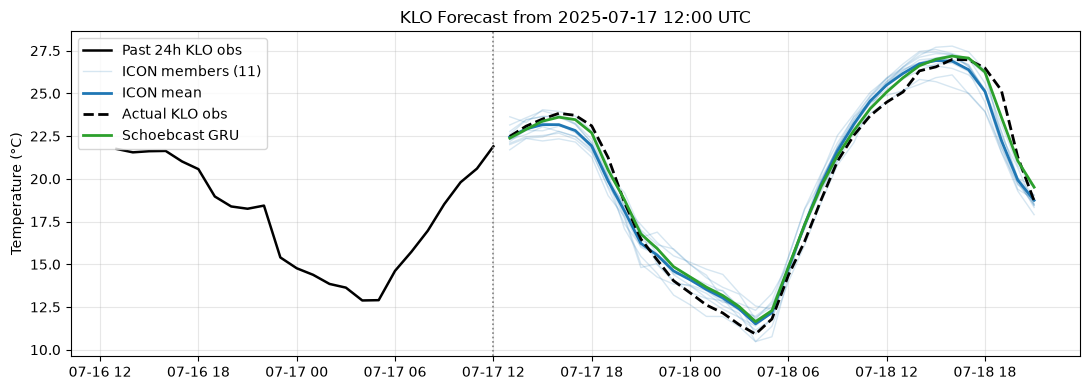

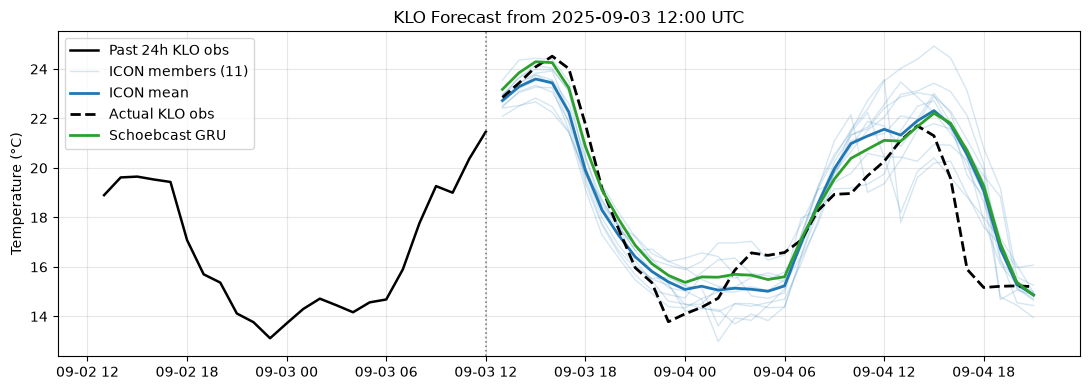

In [19]:
for test_k in range(100, 420, 40):
    utils.plot_sample_forecast(
        raw,
        run_idx=int(splits["test"][test_k]),
        extra_preds={"Schoebcast GRU": test_preds[test_k]},
    )

In [16]:
ckpt_path = model.save_checkpoint(net, scaler)
print("Saved checkpoint to:", ckpt_path)

Saved checkpoint to: C:\Users\marco\Documents\Programmieren\vibeweather\schoebcast\models\schoebcast_klo_gru.pt
